# Uniform Cost Search (UCS)

## 1. Introduction

**Uniform Cost Search (UCS)** is an uninformed search algorithm that expands the node with the lowest path cost first.

### Key Properties

- **Type:** Uninformed Search
- **Strategy:** Expands the least-cost node first
- **Data Structure:** Priority Queue (min-heap)
- **Complete:** Yes — it will find a solution if one exists, given enough time and memory
- **Optimal:** Yes — it finds the least-cost solution if the cost of each step is non-negative

### Learning Objectives

1. Understand how UCS explores a graph.
2. Implement UCS using a priority queue.
3. Analyze the time and space complexity of UCS.
4. Compare UCS with other search algorithms like BFS and DFS.
5. Apply UCS to real-world problems, such as pathfinding in weighted graphs.

## 2. Graph Representation

A **graph** contains vertices (nodes) connected by edges. We represent a directed graph using a Python **Adjacency List**: each key stores the outgoing neighbors of a node.

We will reuse the **same graph** from our BFS & The Other notebooks, so comparing both algorithms is easy.

**Search Problem:** Find a path from `S` (start) to `G` (goal). Unlike BFS, DFS is not guaranteed to choose the path with the fewest edges.

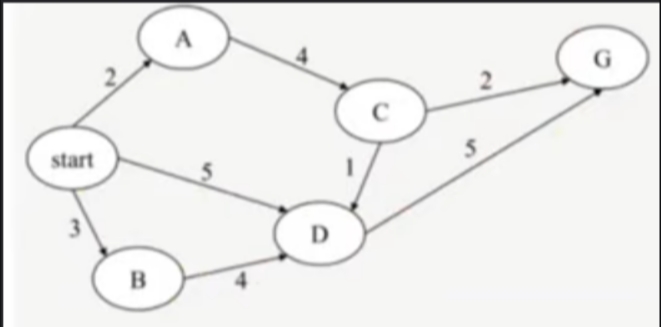

In [1]:
graph = {
    'S': [('A', 2), ('B', 3), ('D', 5)],
    'A': [('C', 4)],
    'B': [('D', 4)],
    'C': [('G', 1), ('D', 2)],
    'D': [('G', 5)],
    'G': []
}

### Understanding the Adjacency List

```python
'S': ['B', 'D', 'A']
```

This means `S` has outgoing edges to `B`, `D`, and `A` **in that listed order**.

```python
'G': []
```

This means `G` has no outgoing edges.

### Neighbor Order Matters

Our implementation of UCS will expand neighbors in the order they are listed in the adjacency list. This is important because it can affect the order in which nodes are explored and, consequently, the path found.

## 3. How UCS Works

UCS (Uniform Cost Search) explores the least-cost paths first, expanding the node with the lowest path cost before exploring other possible branches.

### Algorithm Steps

1. Initialize a priority queue (min-heap) and add the start node with a path cost of 0.
2. While the priority queue is not empty:
   - Dequeue the node with the lowest path cost.
   - If this node is the goal, return the path and its cost.
   - Otherwise, expand the node by adding its neighbors to the priority queue with their respective path costs.
3. Repeat until the goal is found or the queue is empty.
4. If the queue is empty and the goal has not been found, return failure.

`The algorithm guarantees that the first time the goal node is dequeued, it will be via the least-cost path.`

In [2]:
def path_cost(path):
    return sum(edge_cost for node, edge_cost in path)

In [8]:
import heapq

def ucs(graph: dict, start, goal) -> list | None:
    if start not in graph or goal not in graph:
        return None

    queue = [(0, [ (start, 0) ])]
    visited = set()

    while queue:
        cost, path = heapq.heappop(queue)
        node = path[-1][0]

        if node == goal:
            return path

        if node not in visited:
            visited.add(node)

            for neighbor, edge_cost in graph[node]:
                new_path = path + [(neighbor, edge_cost)]
                new_cost = path_cost(new_path)
                heapq.heappush(queue, (new_cost, new_path))

    return None

## 4. Running UCS

Run UCS on the graph from `S` to `G`.

UCS will explore the least-cost paths first, expanding nodes with the lowest path costs.

**Expected Result:** `S -> A -> C -> G` (3 edges).

In [14]:
path = ucs(graph, 'S', 'G')

nodes = [node for node, cost in path] if path else []
print("UCS Path:", " -> ".join(nodes) if nodes else "Not Found")
print("Path Length:", len(nodes) - 1 if nodes else "N/A")

UCS Path: S -> A -> C -> G
Path Length: 3


## 5. Step-by-Step Execution

Let's trace UCS from `S` to `G` using the **same variable names** as our implementation.

The `queue` is a priority queue managed by `heapq`. The path with the **lowest total cost** is popped next. Each queue entry has the form `(cost, path)`, where `path` stores `(node, edge_cost)` tuples. The table shows `queue` **after expansion**, and `visited` **after the current node has been marked**.

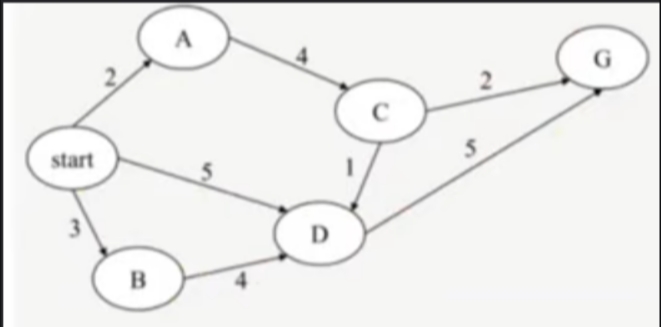

| Step | `node` | `cost` | `path` | `queue` (After Expansion) | `visited` |
|---|---|---:|---|---|---|
| Initial | `—` | `—` | `—` | `[(0, [('S', 0)])]` | `{}` |
| 1 | `'S'` | `0` | `[('S', 0)]` | `[(1, [('S', 0), ('A', 1)]), (4, [('S', 0), ('B', 4)])]` | `{'S'}` |
| 2 | `'A'` | `1` | `[('S', 0), ('A', 1)]` | `[(2, [('S', 0), ('A', 1), ('B', 1)]), (4, [('S', 0), ('B', 4)]), (6, [('S', 0), ('A', 5)])]` | `{'S', 'A'}` |
| 3 | `'B'` | `2` | `[('S', 0), ('A', 1), ('B', 1)]` | `[(3, [('S', 0), ('A', 1), ('B', 1), ('G', 1)]), (4, [('S', 0), ('B', 4)]), (6, [('S', 0), ('A', 5)])]` | `{'S', 'A', 'B'}` |
| 4 | `'G'` | `3` | `[('S', 0), ('A', 1), ('B', 1), ('G', 1)]` | **Goal found** | `{'S', 'A', 'B'}` |

**Note:** `heapq` guarantees that the smallest-priority entry is at the front of the heap, but the remaining entries are not necessarily fully sorted. The table displays the heap's internal list representation. The values in `visited` are shown in a readable order.

### Observations

- **Step 1:** UCS pops `S` with cost `0` and adds paths to `A` with cost `1` and `B` with cost `4`.
- **Step 2:** UCS pops `A` with cost `1`, then adds a new path to `B` with total cost `2` and a path to `G` with total cost `6`.
- **Step 3:** UCS pops `B` with cost `2` and adds a path to `G` with total cost `3`. Notice that another path to `B` with cost `4` is still waiting in the queue.
- **Step 4:** UCS pops `G` with cost `3` and returns `path`. Since UCS expands paths in increasing cost order, this is the least-cost solution for a graph with non-negative edge costs.

### Final Result

**Returned `path`:** `[('S', 0), ('A', 1), ('B', 1), ('G', 1)]`

**Total Path Cost:** `0 + 1 + 1 + 1 = 3`

**Number of Edges:** `len(path) - 1 = 3`

### Understanding the Variables

- **`queue`:** Paths waiting to be explored, prioritized by their total cost (lowest first).
- **`visited`:** Nodes that have already been expanded.
- **`cost`:** The total cost used as the priority when the current path is popped.
- **`path`:** The current path, stored as `(node, edge_cost)` tuples.
- **`node`:** The current node, obtained using `path[-1][0]`.
- **`neighbor`:** A node reachable through an outgoing edge.
- **`edge_cost`:** The cost of moving from `node` to `neighbor`.
- **`new_path`:** The current path extended with one neighbor.
- **`new_cost`:** The total cost of the extended path, calculated by `path_cost(new_path)`.

### Discovered vs. Expanded Nodes

- **Added to `queue`:** A path is waiting to be processed; its final node may not have been expanded yet.
- **Expanded:** A path is popped from `queue`, and its node is marked as visited before its neighbors are examined.
- **Multiple paths:** The same node can appear in multiple queued paths. In this implementation, `visited` prevents expanding a node more than once, but duplicate paths can remain in `queue`.
- **Optimality:** UCS finds the least-cost path when edge costs are non-negative, provided the implementation handles stale or duplicate entries correctly. In this particular trace, the first popped occurrence of each node has the lowest cost.

In [15]:
# Not import function, but for tracing the UCS process
def ucs_trace(graph, start, goal):
    if start not in graph or goal not in graph:
        return None

    queue = [(0, [ (start, 0) ])]
    visited = set()
    step = 0

    print(f"{'Step':<5} {'node':<10} {'cost':<10} {'path':<30} {'queue (After Expansion)':<50} {'visited':<20}")
    print("-" * 150)

    while queue:
        cost, path = heapq.heappop(queue)
        node = path[-1][0]

        if node == goal:
            return path

        if node not in visited:
            visited.add(node)

            # Prepare the queue for display
            queue_display = [(c, p) for c, p in queue]
            queue_display_str = str(queue_display)

            print(f"{step:<5} {node:<10} {cost:<10} {str(path):<30} {queue_display_str:<50} {str(visited):<20}")

            for neighbor, edge_cost in graph[node]:
                new_path = path + [(neighbor, edge_cost)]
                new_cost = path_cost(new_path)
                heapq.heappush(queue, (new_cost, new_path))

            step += 1

    return None

ucs_trace(graph, 'S', 'G')

Step  node       cost       path                           queue (After Expansion)                            visited             
------------------------------------------------------------------------------------------------------------------------------------------------------
0     S          0          [('S', 0)]                     []                                                 {'S'}               
1     A          2          [('S', 0), ('A', 2)]           [(3, [('S', 0), ('B', 3)]), (5, [('S', 0), ('D', 5)])] {'S', 'A'}          
2     B          3          [('S', 0), ('B', 3)]           [(5, [('S', 0), ('D', 5)]), (6, [('S', 0), ('A', 2), ('C', 4)])] {'B', 'S', 'A'}     
3     D          5          [('S', 0), ('D', 5)]           [(6, [('S', 0), ('A', 2), ('C', 4)]), (7, [('S', 0), ('B', 3), ('D', 4)])] {'D', 'B', 'S', 'A'}
4     C          6          [('S', 0), ('A', 2), ('C', 4)] [(7, [('S', 0), ('B', 3), ('D', 4)]), (10, [('S', 0), ('D', 5), ('G', 5)])] {'A', 'C', 'B', '

[('S', 0), ('A', 2), ('C', 4), ('G', 1)]

## 6. Complexity Analysis

For **standard Uniform Cost Search (UCS)**, using an adjacency list and a priority queue:

- **Time:** Typically `O((V + E) log V)` with a priority queue that supports efficient priority updates. With Python's `heapq`, which does not support decrease-key directly, the implementation may instead take `O(V + E log E)` when using best-cost tracking and skipping stale entries.
- **Space:** `O(V + E)` in the worst case for the graph-search bookkeeping and priority queue, depending on the implementation.

Where `V` is the number of reachable vertices and `E` is the number of outgoing edges examined. These bounds assume non-negative edge costs.

### Our Path-Based Implementation

```python
new_path = path + [(neighbor, edge_cost)]
new_cost = path_cost(new_path)
heapq.heappush(queue, (new_cost, new_path))
```

Our educational implementation has additional time and memory overhead:

- **Path copying:** `path + [(neighbor, edge_cost)]` creates a new list for each generated path, taking time proportional to the current path length.
- **Repeated cost calculation:** `path_cost(new_path)` sums all edge costs in the new path instead of reusing the current total cost.
- **Duplicate paths:** Multiple paths to the same node can remain in `queue`, increasing the number of entries that must be stored and processed.
- **Priority queue overhead:** Each insertion and removal requires heap operations.

If `P` is the total number of path entries generated and processed, and `L` is the maximum path length, path copying and repeated cost calculation can require up to `O(P × L)` time, in addition to heap operations. Auxiliary space can reach `O(P × L)` because the queue stores complete path copies.

In graphs with cycles, this particular implementation can generate many redundant paths. Its `visited` set prevents expanding a node more than once, but it does not prevent duplicate entries from being inserted into the queue.

### UCS vs. BFS vs. DFS

| Property | BFS | DFS | UCS |
|---|---|---|---|
| Frontier | Queue (FIFO) | Stack (LIFO) | Priority queue |
| Next node selected | Earliest inserted | Latest inserted | Lowest cumulative cost |
| Considers edge costs | No | No | Yes |
| Finds shortest path by number of edges | Yes, for unweighted graphs | Not guaranteed | Not necessarily |
| Finds least-cost path | Only when edge costs are equal | Not guaranteed | Yes, with non-negative edge costs |
| Typical traversal time | `O(V + E)` | `O(V + E)` | Depends on edge costs and priority queue implementation |

**Challenge:** Can you optimize UCS by tracking the cumulative cost directly instead of calling `path_cost()` each time? How would maintaining a `best_cost` dictionary reduce unnecessary work and duplicate path expansions?

# QUIZ - Time

> TO Check your Understanding

## 1. Predict the Output

Consider the following weighted graph:

```python
graph = {
    'S': [('A', 1), ('B', 4)],
    'A': [('B', 1), ('G', 5)],
    'B': [('G', 1)],
    'G': []
}
```

**Question 1:** What does `ucs(graph, 'S', 'G')` return?

**Question 2:** What does `ucs(graph, 'S', 'B')` return?

**Question 3:** What does `ucs(graph, 'G', 'S')` return?

**Question 4 (Think):** UCS initially adds paths to `A` with cost `1` and `B` with cost `4`. Which node is expanded next, and why?

**Question 5 (Challenge):** There are two paths from `S` to `G`:

- `S → A → G`, with total cost `1 + 5 = 6`.
- `S → A → B → G`, with total cost `1 + 1 + 1 = 3`.

Which path should UCS return, and why doesn't choosing the path with fewer edges necessarily produce the cheapest solution?

Predict the answers before running the next cell.

In [ ]:
test_cases = [
    ('S', 'G'),
    ('S', 'B'),
    ('G', 'S')
]

for start, goal in test_cases:
    result = ucs(graph, start, goal)
    print(f"ucs(graph, '{start}', '{goal}') = {result}")

print("UCS explores the path with the lowest cumulative cost first.")

## 2. Coding Challenge — Fill in the Missing Code

Complete the missing parts of the UCS implementation.

Your task is to implement UCS using:

- A **priority queue** managed by Python's `heapq`.
- A dictionary to track the best known cost for each node.
- Path tracking and goal checking.
- Cumulative path costs to prioritize the cheapest path first.

### Rules

1. Replace every `____` marked `# type: ignore , TODO` with the correct Python expression or method name.
2. Do not change the function name or parameters.
3. Do not copy the complete implementation above.
4. Run the automated tests after filling in all blanks.

**Goal:** Make all tests pass. The tests check both the returned path and the handling of alternative routes with different costs.

In [ ]:
def ucs_challenge(graph: dict, start, goal) -> list | None:
    if start not in graph or goal not in graph:
        return None

    if start == goal:
        return [(start, 0)]

    queue = [(0, [(start, 0)])]
    best_cost = {start: 0}

    while ____:  # type: ignore , TODO
        cost, path = heapq.____(queue)  # type: ignore , TODO
        node = path[-1][____]  # type: ignore , TODO

        if cost > best_cost.get(node, float("inf")):
            ____  # type: ignore , TODO

        if node == ____:  # type: ignore , TODO
            return ____  # type: ignore , TODO

        for neighbor, edge_cost in graph.get(node, []):
            new_cost = ____  # type: ignore , TODO

            if new_cost < best_cost.get(neighbor, float("inf")):
                best_cost[neighbor] = ____
                new_path = path + [(neighbor, edge_cost)]
                heapq.____(queue, (new_cost, new_path))  # type: ignore , TODO

    return ____  # type: ignore , TODO

In [ ]:
test_cases = [
    ("S to G", graph, 'S', 'G',
     [('S', 0), ('A', 1), ('B', 1), ('G', 1)]),
    ("S to B", graph, 'S', 'B',
     [('S', 0), ('A', 1), ('B', 1)]),
    ("S to S", graph, 'S', 'S', [('S', 0)]),
    ("G to S", graph, 'G', 'S', None),
    ("Unknown goal", graph, 'S', 'X', None),
    ("Cheaper route", {
        'S': [('A', 5), ('B', 1)],
        'A': [('G', 1)],
        'B': [('A', 1)],
        'G': []
    }, 'S', 'G',
     [('S', 0), ('B', 1), ('A', 1), ('G', 1)])
]

passed = 0

for name, test_graph, start, goal, expected in test_cases:
    try:
        result = ucs_challenge(test_graph, start, goal)
        success = result == expected

        if success:
            passed += 1

        print(f"{'PASS' if success else 'FAIL'} | {name}")
        if not success:
            print(f"   Expected: {expected}")
            print(f"   Received: {result}")

    except Exception as error:
        print(f"ERROR | {name}: {type(error).__name__}: {error}")

print(f"\nFinal Score: {passed}/{len(test_cases)}")
